# Air Quality Index (AQI) Prediction Using Machine Learning

- This project uses the `city_day.csv` dataset to analyze air pollution and predict Air Quality Index (AQI).
- The dataset contains pollutant measurements such as PM2.5, PM10, NO2, CO, SO2 and O3.
- Five machine learning regression algorithms will be trained and compared to identify the best model.

## 1. Importing Required Libraries

- Python libraries such as Pandas, NumPy, Matplotlib and Seaborn are imported for data processing and visualization.
- Scikit-learn and XGBoost are used for building and evaluating machine learning models.
- Joblib is imported to save the final trained model.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from xgboost import XGBRegressor
import joblib
import warnings
warnings.filterwarnings("ignore")
print("All libraries imported successfully.")

All libraries imported successfully.


## 2. Loading the Dataset

- The `city_day.csv` file is loaded using Pandas.
- Loading the dataset allows us to inspect and analyze the air-quality observations.
- The first few rows are displayed to understand the structure of the data.

In [5]:
df = pd.read_csv("C:/Users/HP/OneDrive/Desktop/Air_Quality_Project/city_day.csv")
print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Shape: (29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


## 3.Understanding the Dataset

The dataset contains daily air-quality observations from different cities in India.

The variables include pollutant concentrations such as:

- PM2.5
- PM10
- NO
- NO2
- NOx
- NH3
- CO
- SO2
- O3
- Benzene
- Toluene
- Xylene

The dataset also contains:

- City
- Date
- AQI
- AQI_Bucket

#Target Variable

The target variable for this project is:

**AQI**

The objective is to predict AQI from the available pollutant and temporal features.

## 4. Checking Dataset Shape

- The shape of the dataset gives the total number of rows and columns.
- Rows represent daily observations, while columns represent different variables.
- This helps us understand the size of the dataset before further analysis.

In [7]:
print("Number of rows    :", df.shape[0])
print("Number of columns :", df.shape[1])
print("Dataset shape     :", df.shape)

Number of rows    : 29531
Number of columns : 16
Dataset shape     : (29531, 16)


## 5. Checking Column Names

- The column names identify the different pollutants, date information and AQI-related variables.
- Understanding the columns helps us decide which variables can be used as machine learning features.
- The dataset contains both numerical and categorical variables.

In [8]:
print("Columns in city_day.csv:\n")
for number, column in enumerate(df.columns, start=1):
    print(f"{number}. {column}")

Columns in city_day.csv:

1. City
2. Date
3. PM2.5
4. PM10
5. NO
6. NO2
7. NOx
8. NH3
9. CO
10. SO2
11. O3
12. Benzene
13. Toluene
14. Xylene
15. AQI
16. AQI_Bucket


## 7. Checking Data Types

- Data types are checked to identify numerical, categorical and date-related variables.
- Correct data types are important because machine learning algorithms require properly formatted input data.
- The Date column will later be converted into datetime format.

In [9]:
print(df.dtypes)

City              str
Date              str
PM2.5         float64
PM10          float64
NO            float64
NO2           float64
NOx           float64
NH3           float64
CO            float64
SO2           float64
O3            float64
Benzene       float64
Toluene       float64
Xylene        float64
AQI           float64
AQI_Bucket        str
dtype: object


# 8. Dataset Information

- The `info()` function provides information about columns, data types and non-null values.
- It helps identify columns containing missing observations.
- This information is useful for planning the preprocessing stage.

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  str    
 1   Date        29531 non-null  str    
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  str    
dtypes: float64(13), str(3)
memory usage: 3.6 MB


### 9. Statistical Summary

- Descriptive statistics are used to understand the numerical variables in the dataset.
- Measures such as mean, standard deviation, minimum and maximum values are examined.
- This also helps identify unusual ranges and possible extreme observations.

In [12]:
display(df.describe())

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,24933.000000,18391.000000,25949.000000,25946.000000,25346.000000,19203.000000,27472.000000,25677.000000,25509.000000,23908.000000,21490.000000,11422.000000,24850.000000
mean,67.450578,118.127103,17.574730,28.560659,32.309123,23.483476,2.248598,14.531977,34.491430,3.280840,8.700972,3.070128,166.463581
std,64.661449,90.605110,22.785846,24.474746,31.646011,25.684275,6.962884,18.133775,21.694928,15.811136,19.969164,6.323247,140.696585
min,0.040000,0.010000,0.020000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000,0.000000,0.000000,0.000000,13.000000
25%,28.820000,56.255000,5.630000,11.750000,12.820000,8.580000,0.510000,5.670000,18.860000,0.120000,0.600000,0.140000,81.000000
50%,48.570000,95.680000,9.890000,21.690000,23.520000,15.850000,0.890000,9.160000,30.840000,1.070000,2.970000,0.980000,118.000000
75%,80.590000,149.745000,19.950000,37.620000,40.127500,30.020000,1.450000,15.220000,45.570000,3.080000,9.150000,3.350000,208.000000
max,949.990000,1000.000000,390.680000,362.210000,467.630000,352.890000,175.810000,193.860000,257.730000,455.030000,454.850000,170.370000,2049.000000


### 10. Understanding the City Variable

- The dataset contains air-quality observations from multiple cities in India.
- The number of unique cities helps us understand the geographical coverage of the dataset.
- City information is useful for exploratory analysis of differences in pollution levels.

In [13]:
print("Number of unique cities:", df["City"].nunique())
print("\nCities:")
print(df["City"].unique())

Number of unique cities: 26

Cities:
<StringArray>
[         'Ahmedabad',             'Aizawl',          'Amaravati',
           'Amritsar',          'Bengaluru',             'Bhopal',
       'Brajrajnagar',         'Chandigarh',            'Chennai',
         'Coimbatore',              'Delhi',          'Ernakulam',
           'Gurugram',           'Guwahati',          'Hyderabad',
             'Jaipur',         'Jorapokhar',              'Kochi',
            'Kolkata',            'Lucknow',             'Mumbai',
              'Patna',           'Shillong',            'Talcher',
 'Thiruvananthapuram',      'Visakhapatnam']
Length: 26, dtype: str


### 11. Exploratory Data Analysis — AQI Distribution

- The distribution of AQI values is visualized using a histogram.
- This helps us understand the range and frequency of different AQI values.
- It can also reveal skewness and unusually high or low AQI observations.

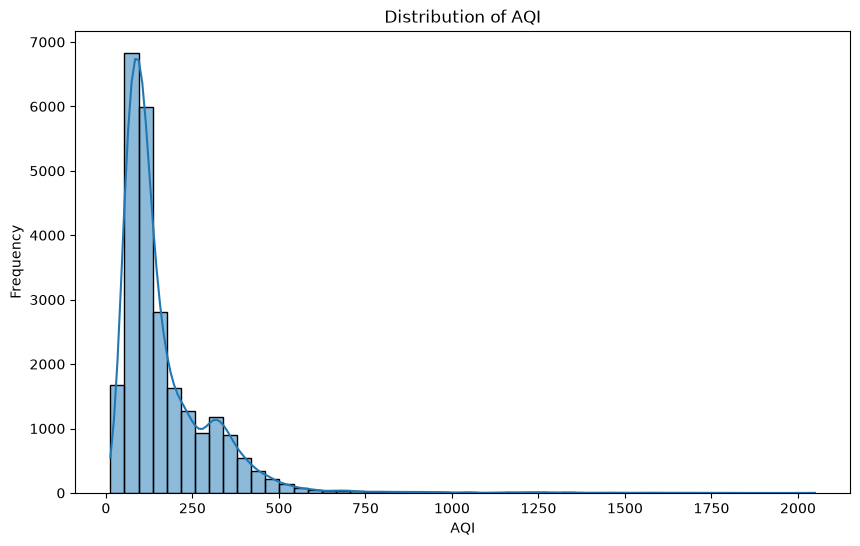

In [14]:
plt.figure(figsize=(10, 6))
sns.histplot(
    df["AQI"].dropna(),
    bins=50,
    kde=True
)
plt.title("Distribution of AQI")
plt.xlabel("AQI")
plt.ylabel("Frequency")
plt.show()

### 12. Exploratory Data Analysis — AQI by City

- The average AQI is calculated separately for each city.
- This helps compare pollution levels between different cities.
- Differences may occur because of traffic, industries, weather and other environmental factors.

In [15]:
city_aqi = (
    df.groupby("City")["AQI"]
    .mean()
    .sort_values(ascending=False)
)

display(city_aqi)

City
Ahmedabad             452.122939
Delhi                 259.487744
Patna                 240.782042
Gurugram              225.123882
Lucknow               217.973059
Talcher               172.886819
Jorapokhar            159.251621
Brajrajnagar          150.280505
Kolkata               140.566313
Guwahati              140.111111
Jaipur                133.679159
Bhopal                132.827338
Amritsar              119.920959
Visakhapatnam         117.269855
Chennai               114.502654
Hyderabad             109.207447
Mumbai                105.352258
Kochi                 104.284810
Chandigarh             96.498328
Amaravati              95.299643
Bengaluru              94.318325
Ernakulam              92.359477
Thiruvananthapuram     75.878327
Coimbatore             73.023256
Shillong               53.795122
Aizawl                 34.765766
Name: AQI, dtype: float64

### 13. Correlation Analysis

- Correlation analysis is used to study relationships between numerical variables.
- It helps identify how strongly pollutant measurements are related to AQI.
- A heatmap provides an easy visual representation of these relationships.

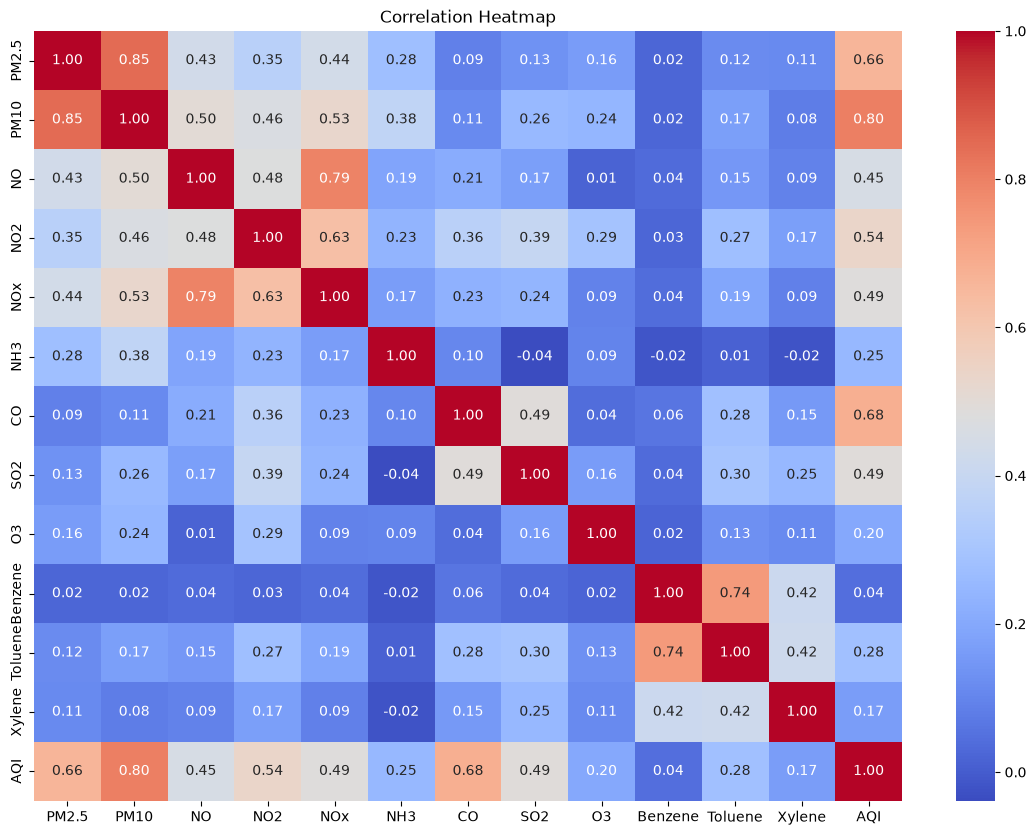

In [16]:
numeric_df = df.select_dtypes(include=np.number)
plt.figure(figsize=(14, 10))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)
plt.title("Correlation Heatmap")
plt.show()

### 14. Missing Value Analysis

- Missing values are identified and their percentage is calculated for each column.
- Missing sensor measurements are common in real-world environmental datasets.
- This analysis helps determine the appropriate preprocessing method.

In [17]:
missing_count = df.isnull().sum()
missing_percentage = (
    missing_count / len(df) * 100
)
missing_table = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percentage
})
display(
    missing_table.sort_values(
        "Missing Values",
        ascending=False
    )
)

,Missing Values,Missing Percentage
Xylene,18109,61.322001
PM10,11140,37.723071
NH3,10328,34.973418
Toluene,8041,27.229014
Benzene,5623,19.041008
AQI,4681,15.851139
AQI_Bucket,4681,15.851139
PM2.5,4598,15.570079
NOx,4185,14.171549
O3,4022,13.619586


### 15. Duplicate Analysis

- Duplicate rows are checked to determine whether identical observations occur in the dataset.
- Duplicate records can unnecessarily influence data analysis and model training.
- If duplicates are found, they will be removed during preprocessing.

In [18]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


### 16. Outlier Analysis

- Boxplots are used to identify possible extreme values in pollutant measurements.
- High pollution values may represent genuine pollution events rather than errors.
- Therefore, potential outliers are inspected instead of automatically deleting them.

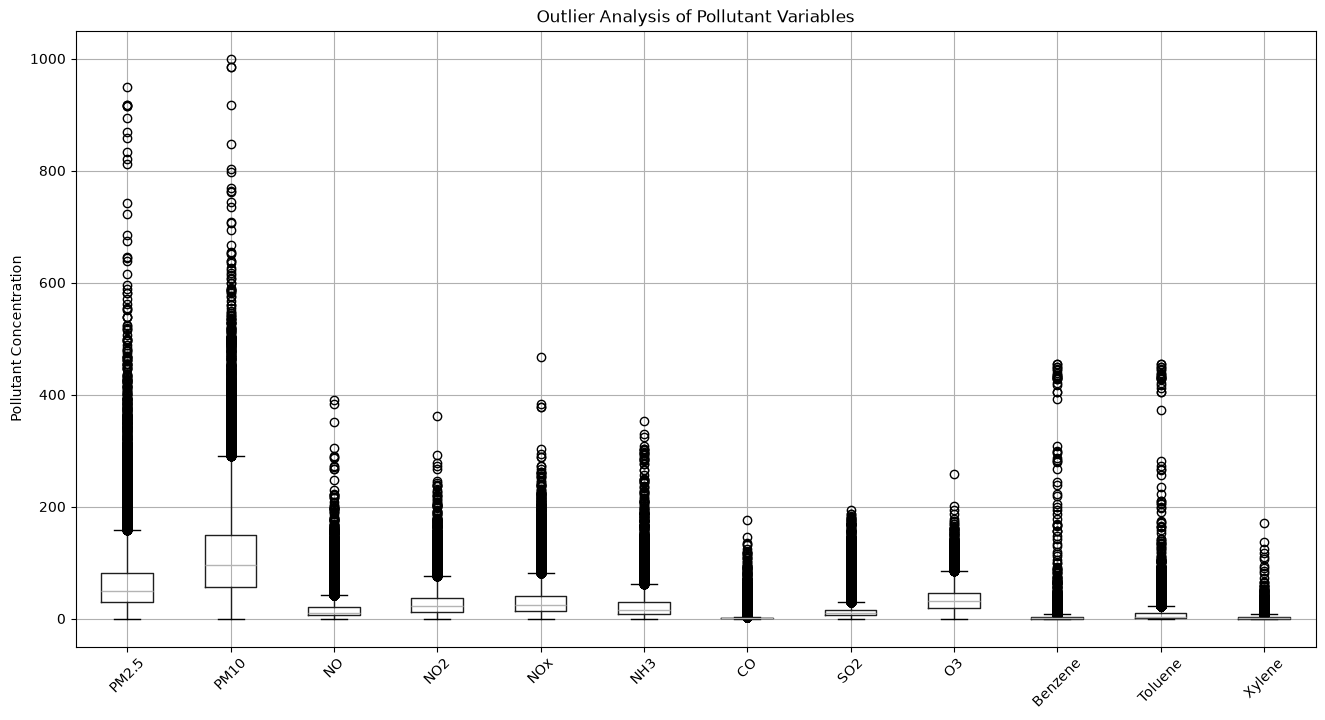

In [20]:
pollutants = [
    "PM2.5",
    "PM10",
    "NO",
    "NO2",
    "NOx",
    "NH3",
    "CO",
    "SO2",
    "O3",
    "Benzene",
    "Toluene",
    "Xylene"
]

plt.figure(figsize=(16, 8))

df[pollutants].boxplot()

plt.title("Outlier Analysis of Pollutant Variables")
plt.ylabel("Pollutant Concentration")

plt.xticks(rotation=45)

plt.show()

### 17. Handling Duplicate Records

- Exact duplicate rows are removed from the dataset if they are present.
- Removing duplicates prevents repeated observations from receiving unnecessary importance.
- If no duplicates exist, the dataset remains unchanged.

In [21]:
before_duplicates = df.shape[0]
df = df.drop_duplicates()
after_duplicates = df.shape[0]
print("Rows before removing duplicates:", before_duplicates)
print("Rows after removing duplicates :", after_duplicates)
print("Duplicate rows removed          :", before_duplicates - after_duplicates)

Rows before removing duplicates: 29531
Rows after removing duplicates : 29531
Duplicate rows removed          : 0


### 18. Handling Missing Values

- Rows with missing AQI values are removed because AQI is the target variable.
- Missing numerical pollutant values are replaced using their median values.
- Median imputation is less affected by extreme values than mean imputation.

In [22]:
# Remove rows where AQI is missing
df = df.dropna(subset=["AQI"])

print("Rows after removing missing AQI:", df.shape[0])

# Numerical pollutant columns
pollutant_columns = [
    "PM2.5",
    "PM10",
    "NO",
    "NO2",
    "NOx",
    "NH3",
    "CO",
    "SO2",
    "O3",
    "Benzene",
    "Toluene",
    "Xylene"
]

# Fill missing pollutant values using median
for column in pollutant_columns:
    df[column] = df[column].fillna(df[column].median())

print("\nMissing values after treatment:")
display(df[pollutant_columns + ["AQI"]].isnull().sum())

Rows after removing missing AQI: 24850

Missing values after treatment:


PM2.5      0
PM10       0
NO         0
NO2        0
NOx        0
NH3        0
CO         0
SO2        0
O3         0
Benzene    0
Toluene    0
Xylene     0
AQI        0
dtype: int64

### 19. Checking the Cleaned Dataset

- The dataset is checked again after handling duplicates and missing values.
- This confirms that the preprocessing operations were applied correctly.
- The cleaned data is now ready for feature engineering.

In [23]:
print("Cleaned dataset shape:", df.shape)

display(df.head())

Cleaned dataset shape: (24850, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
28,Ahmedabad,2015-01-29,83.13,96.18,6.93,28.71,33.72,16.31,6.93,49.52,59.76,0.02,0.00,3.14,209.0,Poor
29,Ahmedabad,2015-01-30,79.84,96.18,13.85,28.68,41.08,16.31,13.85,48.49,97.07,0.04,0.00,4.81,328.0,Very Poor
30,Ahmedabad,2015-01-31,94.52,96.18,24.39,32.66,52.61,16.31,24.39,67.39,111.33,0.24,0.01,7.67,514.0,Severe
31,Ahmedabad,2015-02-01,135.99,96.18,43.48,42.08,84.57,16.31,43.48,75.23,102.70,0.40,0.04,25.87,782.0,Severe
32,Ahmedabad,2015-02-02,178.33,96.18,54.56,35.31,72.80,16.31,54.56,55.04,107.38,0.46,0.06,35.61,914.0,Severe


### 20. Date Preprocessing

- The Date column is converted from text format into a proper datetime format.
- Datetime conversion allows useful information such as year, month and day to be extracted.
- These time-based features can help the model identify temporal patterns.

In [24]:
df["Date"] = pd.to_datetime(df["Date"])

print("Date data type:", df["Date"].dtype)

Date data type: datetime64[us]


### 21. Feature Engineering

- New features such as Year, Month, Day and DayOfWeek are extracted from the Date column.
- These features may capture seasonal and weekly patterns in air pollution.
- Feature engineering can improve the information available to machine learning models.

In [25]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["DayOfWeek"] = df["Date"].dt.dayofweek

display(
    df[
        ["Date", "Year", "Month", "Day", "DayOfWeek"]
    ].head(10)
)

,Date,Year,Month,Day,DayOfWeek
28,2015-01-29,2015,1,29,3
29,2015-01-30,2015,1,30,4
30,2015-01-31,2015,1,31,5
31,2015-02-01,2015,2,1,6
32,2015-02-02,2015,2,2,0
33,2015-02-03,2015,2,3,1
34,2015-02-04,2015,2,4,2
35,2015-02-05,2015,2,5,3
36,2015-02-06,2015,2,6,4
37,2015-02-07,2015,2,7,5


### 22. Understanding AQI_Bucket

- `AQI_Bucket` represents AQI categories such as Good, Moderate, Poor and Severe.
- It is not used as an input feature because it is derived from AQI, our target variable.
- Using it could cause **target leakage** and produce misleading model performance.

In [26]:
print("AQI Bucket categories:")

display(
    df["AQI_Bucket"].value_counts()
)

AQI Bucket categories:


AQI_Bucket
Moderate        8829
Satisfactory    8224
Poor            2781
Very Poor       2337
Good            1341
Severe          1338
Name: count, dtype: int64

### 23. Feature Selection

- Pollutant measurements and date-derived features are selected as input variables.
- AQI is selected as the target variable that the models need to predict.
- AQI_Bucket, Date and AQI itself are excluded from the input features to avoid leakage and unsuitable data formats.

In [27]:
features = [
    "PM2.5",
    "PM10",
    "NO",
    "NO2",
    "NOx",
    "NH3",
    "CO",
    "SO2",
    "O3",
    "Benzene",
    "Toluene",
    "Xylene",
    "Year",
    "Month",
    "Day",
    "DayOfWeek"
]

target = "AQI"

print("Selected Features:")
for feature in features:
    print("-", feature)

print("\nTarget:", target)

Selected Features:
- PM2.5
- PM10
- NO
- NO2
- NOx
- NH3
- CO
- SO2
- O3
- Benzene
- Toluene
- Xylene
- Year
- Month
- Day
- DayOfWeek

Target: AQI


### 24. Preparing X and y

- `X` contains the selected input features used for prediction.
- `y` contains the AQI values that the models will learn to predict.
- Separating X and y prepares the data for supervised machine learning.

In [28]:
X = df[features].copy()
y = df[target].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nX columns:")
print(X.columns.tolist())

print("\nTarget:", y.name)

X shape: (24850, 16)
y shape: (24850,)

X columns:
['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'Year', 'Month', 'Day', 'DayOfWeek']

Target: AQI


### 25. Final Data Quality Check

- A final missing-value check is performed on the selected features and target.
- Machine learning models require appropriate and complete input data.
- The selected features should contain zero missing values before model training.

In [29]:
print("Missing values in X:")

display(X.isnull().sum())

print("\nMissing values in y:")

print(y.isnull().sum())

Missing values in X:


PM2.5        0
PM10         0
NO           0
NO2          0
NOx          0
NH3          0
CO           0
SO2          0
O3           0
Benzene      0
Toluene      0
Xylene       0
Year         0
Month        0
Day          0
DayOfWeek    0
dtype: int64


Missing values in y:
0


### 26. Train-Test Split

- The dataset is divided into 80% training data and 20% testing data.
- The training data is used to learn patterns, while the testing data is used to evaluate performance on unseen observations.
- `random_state=42` ensures that the same split can be reproduced.

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Training data:
X_train: (19880, 16)
y_train: (19880,)

Testing data:
X_test: (4970, 16)
y_test: (4970,)


### 27. Model Evaluation Function

- A common evaluation function is created so that all five models are evaluated using the same metrics.
- MAE and RMSE measure prediction error, where lower values are better.
- R² measures the variation explained by the model, where a higher value is better.

In [31]:
def evaluate_model(model, model_name):
    
    # Train model
    model.fit(X_train, y_train)
    
    # Predict test data
    predictions = model.predict(X_test)
    
    # Calculate metrics
    mae = mean_absolute_error(y_test, predictions)
    
    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )
    
    r2 = r2_score(y_test, predictions)
    
    print(f"{model_name}")
    print("-" * len(model_name))
    print(f"MAE  : {mae:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"R²   : {r2:.4f}")
    
    return predictions, mae, rmse, r2

### 28. Linear Regression

- Linear Regression is used as a simple baseline regression model for AQI prediction.
- It assumes a linear relationship between the input pollutant features and AQI.
- Its performance provides a baseline for comparing the more advanced models.

In [32]:
# Create Linear Regression model
linear_model = LinearRegression()

# Train and evaluate the model
linear_predictions, linear_mae, linear_rmse, linear_r2 = evaluate_model(
    linear_model,
    "Linear Regression"
)

Linear Regression
-----------------
MAE  : 31.0008
RMSE : 59.2612
R²   : 0.8082


### 29. Decision Tree Regressor

- A Decision Tree predicts AQI by repeatedly splitting the data based on feature values.
- It can learn nonlinear relationships that Linear Regression may not capture.
- The model is evaluated using MAE, RMSE and R².

In [33]:
# Create Decision Tree model
decision_tree_model = DecisionTreeRegressor(
    random_state=42,
    max_depth=10
)

# Train and evaluate
decision_tree_predictions, decision_tree_mae, decision_tree_rmse, decision_tree_r2 = evaluate_model(
    decision_tree_model,
    "Decision Tree Regressor"
)

Decision Tree Regressor
-----------------------
MAE  : 24.7695
RMSE : 50.2063
R²   : 0.8623


### 30. Random Forest Regressor

- Random Forest combines multiple decision trees to produce a more stable prediction.
- It can capture complex nonlinear relationships between pollutants and AQI.
- The predictions from multiple trees are combined to improve generalization.

In [34]:
# Create Random Forest model
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train and evaluate
random_forest_predictions, random_forest_mae, random_forest_rmse, random_forest_r2 = evaluate_model(
    random_forest_model,
    "Random Forest Regressor"
)

Random Forest Regressor
-----------------------
MAE  : 20.7010
RMSE : 40.5723
R²   : 0.9101


### 31. Gradient Boosting Regressor

- Gradient Boosting builds decision trees sequentially, with each new tree improving previous errors.
- It is useful for learning complex relationships in structured datasets.
- The model is evaluated using MAE, RMSE and R².

In [35]:
# Create Gradient Boosting model
gradient_boosting_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

# Train and evaluate
gradient_boosting_predictions, gradient_boosting_mae, gradient_boosting_rmse, gradient_boosting_r2 = evaluate_model(
    gradient_boosting_model,
    "Gradient Boosting Regressor"
)

Gradient Boosting Regressor
---------------------------
MAE  : 24.3747
RMSE : 44.5516
R²   : 0.8916


### 32. XGBoost Regressor

- XGBoost is an advanced gradient-boosting algorithm designed for efficient prediction on structured data.
- It can learn nonlinear relationships and interactions between pollutant features.
- Its performance is compared with the other four regression algorithms.


In [36]:
# Create XGBoost model
xgboost_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=5,
    random_state=42,
    objective="reg:squarederror",
    n_jobs=-1
)

# Train and evaluate
xgboost_predictions, xgboost_mae, xgboost_rmse, xgboost_r2 = evaluate_model(
    xgboost_model,
    "XGBoost Regressor"
)

XGBoost Regressor
-----------------
MAE  : 21.9911
RMSE : 43.2788
R²   : 0.8977


### 33. Model Evaluation and Comparison

- The five models are compared using MAE, RMSE and R².
- Lower MAE and RMSE indicate smaller prediction errors.
- Higher R² indicates that the model explains more variation in AQI.

In [37]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "XGBoost"
    ],
    
    "MAE": [
        linear_mae,
        decision_tree_mae,
        random_forest_mae,
        gradient_boosting_mae,
        xgboost_mae
    ],
    
    "RMSE": [
        linear_rmse,
        decision_tree_rmse,
        random_forest_rmse,
        gradient_boosting_rmse,
        xgboost_rmse
    ],
    
    "R2": [
        linear_r2,
        decision_tree_r2,
        random_forest_r2,
        gradient_boosting_r2,
        xgboost_r2
    ]
})

results = results.sort_values(
    by="R2",
    ascending=False
).reset_index(drop=True)

display(results)

,Model,MAE,RMSE,R2
0,Random Forest,20.700977,40.572270,0.910103
1,XGBoost,21.991076,43.278794,0.897709
2,Gradient Boosting,24.374699,44.551639,0.891604
3,Decision Tree,24.769485,50.206307,0.862341
4,Linear Regression,31.000755,59.261212,0.808209


### 34. Visual Comparison of Model Performance

- A bar chart is used to compare the R² scores of the five models.
- Visualization makes it easier to identify differences in model performance.
- The model with a higher R² generally provides better predictive performance.

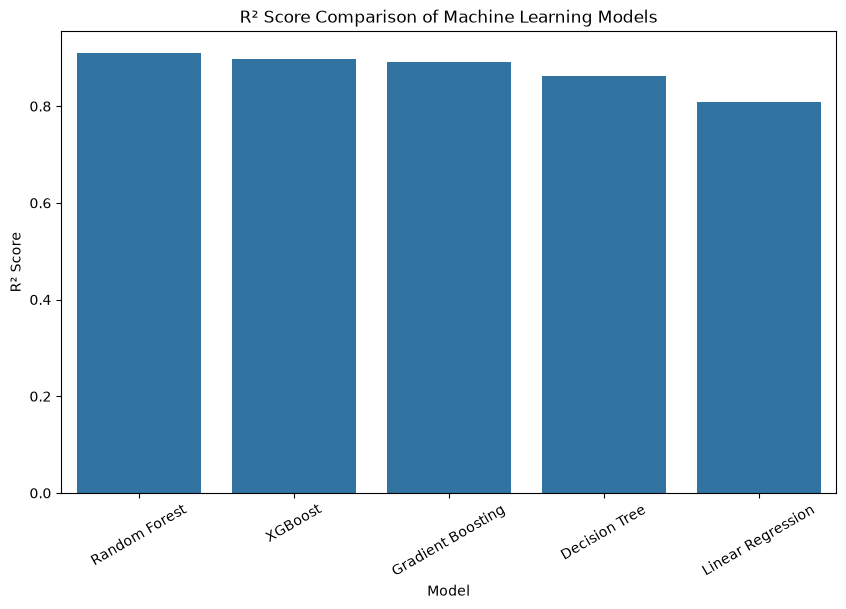

In [38]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results,
    x="Model",
    y="R2"
)

plt.title("R² Score Comparison of Machine Learning Models")
plt.xlabel("Model")
plt.ylabel("R² Score")

plt.xticks(rotation=30)

plt.show()

### 35. Best Model Selection

- The model with the highest R² score is initially selected as the best model.
- MAE and RMSE are also considered to ensure that prediction errors are reasonably low.
- The selected model will be used for further analysis and prediction.

In [39]:
best_model_name = results.loc[
    results["R2"].idxmax(),
    "Model"
]

best_r2 = results["R2"].max()

print("Best Model:", best_model_name)
print("Best R²:", round(best_r2, 4))

Best Model: Random Forest
Best R²: 0.9101


### 36. Selecting the Best Trained Model

- The best-performing model name is matched with its trained model object.
- This model will be used for feature importance, visualization and new-data prediction.
- Keeping the trained model allows us to reuse it without retraining.

In [40]:
model_objects = {
    "Linear Regression": linear_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model,
    "XGBoost": xgboost_model
}

best_model = model_objects[best_model_name]

print("Selected model object:", best_model)

Selected model object: RandomForestRegressor(n_jobs=-1, random_state=42)


### 37. Feature Importance

- Feature importance identifies which input variables contribute most to the model's predictions.
- This helps us understand the role of different pollutants in AQI prediction.
- Higher importance values indicate greater contribution according to the selected model.

In [41]:
if hasattr(best_model, "feature_importances_"):
    
    importance_values = best_model.feature_importances_
    
    feature_importance = pd.DataFrame({
        "Feature": features,
        "Importance": importance_values
    })
    
    feature_importance = feature_importance.sort_values(
        by="Importance",
        ascending=False
    )
    
    display(feature_importance)
    
else:
    # Linear Regression uses coefficients
    importance_values = np.abs(best_model.coef_)
    
    feature_importance = pd.DataFrame({
        "Feature": features,
        "Importance": importance_values
    })
    
    feature_importance = feature_importance.sort_values(
        by="Importance",
        ascending=False
    )
    
    display(feature_importance)

,Feature,Importance
0,PM2.5,0.489364
6,CO,0.365997
1,PM10,0.036086
2,NO,0.035955
8,O3,0.012531
4,NOx,0.010272
7,SO2,0.008166
10,Toluene,0.006501
3,NO2,0.006119
14,Day,0.005843


### 38. Feature Importance Visualization

- The top important features are displayed using a bar chart.
- Visualization makes it easier to identify the most influential variables.
- This provides useful interpretation of the machine learning model.

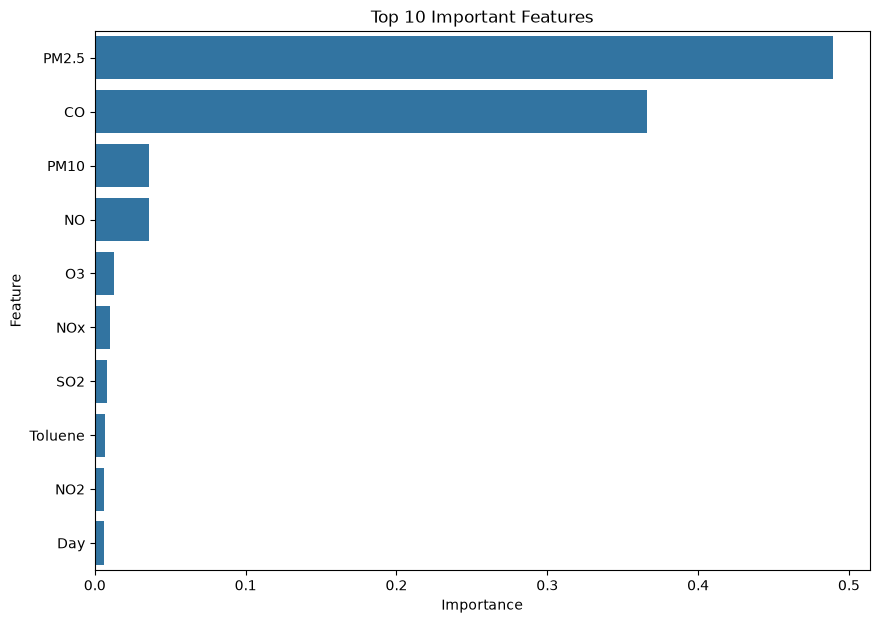

In [42]:
plt.figure(figsize=(10, 7))

top_features = feature_importance.head(10)

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

### 39. Actual vs Predicted AQI

- Actual AQI values are compared with AQI values predicted by the best model.
- Points closer to the diagonal reference line indicate more accurate predictions.
- This visualization helps assess how well the model follows the actual AQI values.

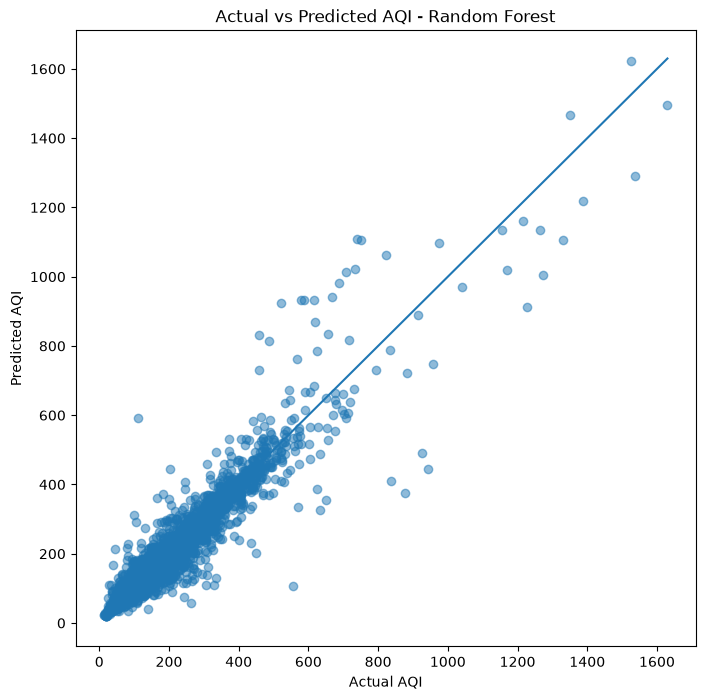

In [43]:
best_predictions = best_model.predict(X_test)

plt.figure(figsize=(8, 8))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.5
)

# Reference line
minimum = min(y_test.min(), best_predictions.min())
maximum = max(y_test.max(), best_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum]
)

plt.title(f"Actual vs Predicted AQI - {best_model_name}")
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")

plt.show()

### 40. Prediction Error Analysis

- Residuals represent the difference between actual AQI and predicted AQI.
- A residual plot helps identify patterns or unusually large prediction errors.
- Residuals distributed around zero generally indicate better model behavior.

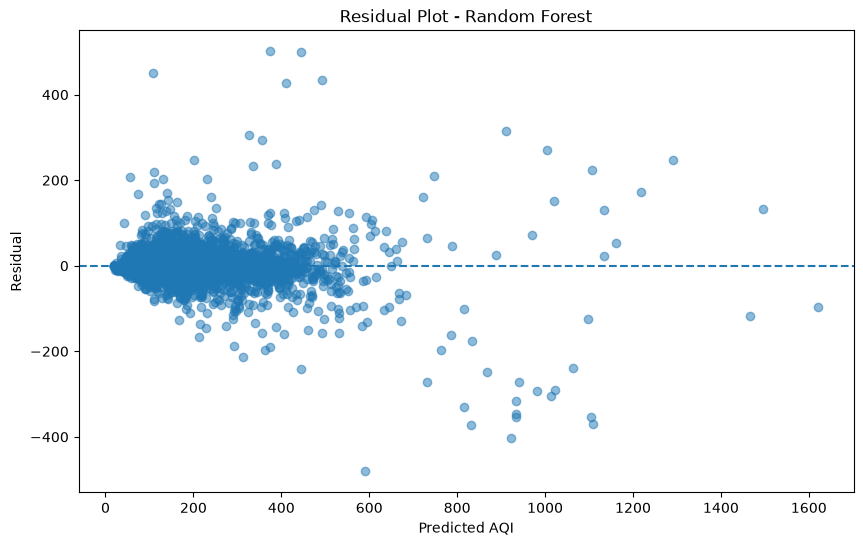

In [44]:
residuals = y_test - best_predictions

plt.figure(figsize=(10, 6))

plt.scatter(
    best_predictions,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title(f"Residual Plot - {best_model_name}")
plt.xlabel("Predicted AQI")
plt.ylabel("Residual")

plt.show()

### 41. Prediction Using New

- A new observation containing pollutant and date-related values is provided to the trained model.
- The model uses the learned patterns to estimate its AQI.
- This demonstrates how the model can be applied to future unseen observations.

In [45]:
new_data = pd.DataFrame({
    "PM2.5": [50.0],
    "PM10": [100.0],
    "NO": [20.0],
    "NO2": [30.0],
    "NOx": [40.0],
    "NH3": [15.0],
    "CO": [1.0],
    "SO2": [20.0],
    "O3": [50.0],
    "Benzene": [2.0],
    "Toluene": [5.0],
    "Xylene": [1.0],
    "Year": [2026],
    "Month": [8],
    "Day": [31],
    "DayOfWeek": [0]
})

predicted_aqi = best_model.predict(new_data)

print("Predicted AQI:", round(predicted_aqi[0], 2))

Predicted AQI: 112.77


### 42. Saving the Trained Model

- The selected best model is saved using the Joblib library.
- Saving the model allows it to be reused later without training it again.
- The saved model can be integrated into a future application or prediction system.

In [46]:
model_filename = "best_aqi_model.pkl"

joblib.dump(best_model, model_filename)

print("Best model saved successfully.")
print("File:", model_filename)

Best model saved successfully.
File: best_aqi_model.pkl


### 43. Loading the Saved Model

- The saved model is loaded back into Python using Joblib.
- A prediction is made using the loaded model to verify that it works correctly.
- This confirms that the trained model can be stored and reused successfully.

In [47]:
loaded_model = joblib.load(model_filename)

loaded_prediction = loaded_model.predict(new_data)

print("Loaded model prediction:", round(loaded_prediction[0], 2))

Loaded model prediction: 112.77


# 44. Final Conclusion

This project developed a machine learning-based system for predicting Air Quality Index (AQI) using the `city_day.csv` dataset.

The dataset was first explored to understand its structure, variables, missing values, duplicate records and potential outliers.

Missing target values were removed, while missing numerical pollutant values were handled using median imputation. The Date variable was converted into datetime format, and additional temporal features such as Year, Month, Day and DayOfWeek were created.

AQI was selected as the target variable. AQI_Bucket was excluded because it is derived from AQI and using it as an input would cause target leakage.

Five regression algorithms were trained:

1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. Gradient Boosting Regressor
5. XGBoost Regressor

The models were evaluated using MAE, RMSE and R².

The best model was selected based primarily on the highest R² score while also considering MAE and RMSE.

Feature importance analysis was performed to identify the variables that contributed most to AQI prediction.

An Actual vs Predicted visualization was created to examine prediction quality.

Finally, the selected model was used to predict AQI for a new unseen observation and was saved using Joblib for future use.

## Final Result

The machine learning approach demonstrates that pollutant measurements can be used to predict AQI and that ensemble-based models can capture nonlinear relationships between air pollutants and AQI.

The selected best model can be reused for future AQI prediction after providing pollutant measurements in the same feature format used during training.